# FGM Prevalence and Attitude Comparison, Kenya, all survey rounds (V2)

Compares where FGM is practised with where it is supported, pooling all survey rounds:

1. **Province level.** Pooled model-based prevalence for the 8 former provinces (women 15–49
   and girls 0–14) against pooled model-based support for continuation among women and men.
2. **Cluster level.** As in V1, cluster-level attitude points over the pooled region
   prevalence polygons. Points come from every DHS round with GPS and the attitude question
   (2008–09, 2014 and 2022; men 2014 and 2022), each fitted with the V1 cluster model and
   shown together. GPS files for DHS 1998 and 2003 are not available.

Run the prevalence notebook and the attitude notebook (women and men) first. Associations
are descriptive, not causal, and DHS GPS points are displaced (up to 2 km urban, 5–10 km
rural).

## 0. Configuration

In [1]:
country_name <- "Kenya"
country_iso3 <- "KEN"
project_root <- if (dir.exists("../02_Data")) ".." else "."
analysis_dir <- file.path(project_root, "02_Data", "processed", country_iso3, "analysis")
outputs_root <- file.path(project_root, "03_Outputs", country_iso3)
output_dir <- file.path(outputs_root, "Prevalence_Attitude_Comparison")
dirs <- list(region = file.path(output_dir, "01_Region_Level"),
             cluster = file.path(output_dir, "02_Cluster_Level"))
for (d in dirs) dir.create(d, recursive = TRUE, showWarnings = FALSE)

shapefile_path <- file.path(project_root, "02_Data", "processed", "KEN", "boundaries", "KEN_provinces.shp")
gps_dir <- file.path(project_root, "02_Data", "raw", "kenya_FGM_Data", "extracted", "GPS")
gps_paths <- c(
  "DHS 2008" = file.path(gps_dir, "KEGE52FL", "KEGE52FL.shp"),
  "DHS 2014" = file.path(gps_dir, "KEGE71FL", "KEGE71FL.shp"),
  "DHS 2022" = file.path(gps_dir, "KEGE8AFL", "KEGE8AFL.shp")
)
stopifnot(all(file.exists(gps_paths)))
region_var_shapefile <- "PROVINCE"
standardize_region <- function(x) toupper(as.character(x)) |> stringr::str_replace_all("[^A-Z ]", " ") |> stringr::str_squish()
k_neighbours <- 6L
posterior_draws <- 300L
round_order <- c("DHS 1998", "DHS 2003", "DHS 2008", "DHS 2014", "DHS 2022")
options(repr.plot.width = 17, repr.plot.height = 9, width = 200)

## 1. Packages

In [2]:
suppressPackageStartupMessages({library(tidyverse); library(survey); library(sf); library(spdep); library(INLA)})
options(survey.lonely.psu = "adjust")
theme_set(ggplot2::theme_minimal(base_size = 12))

## 2. Load pooled region estimates from the V2 notebooks

In [3]:
read_out <- function(...) readr::read_csv(file.path(outputs_root, ...), show_col_types = FALSE)
prevalence_state <- dplyr::bind_rows(
  read_out("Prevalence", "03_Covariate_Adjusted", paste0(country_iso3, "_prevalence_covariate_adjusted_self.csv")) |>
    dplyr::mutate(population = "Women 15-49"),
  read_out("Prevalence", "03_Covariate_Adjusted", paste0(country_iso3, "_prevalence_covariate_adjusted_daughter.csv")) |>
    dplyr::mutate(population = "Girls 0-14")
) |> dplyr::select(region, population, prevalence = model_assisted_prevalence) |>
  dplyr::mutate(population = factor(population, levels = c("Women 15-49", "Girls 0-14")))
attitude_state <- dplyr::bind_rows(
  read_out("Attitude_Women", "03_Model_Estimates", paste0(country_iso3, "_attitude_covariate_adjusted_by_region.csv")) |>
    dplyr::mutate(respondents = "Women's attitudes"),
  read_out("Attitude_Men", "03_Model_Estimates", paste0(country_iso3, "_attitude_covariate_adjusted_by_region.csv")) |>
    dplyr::mutate(respondents = "Men's attitudes")
) |> dplyr::select(region, respondents, support = adjusted_support) |>
  dplyr::mutate(respondents = factor(respondents, levels = c("Women's attitudes", "Men's attitudes")))

boundaries <- sf::st_read(shapefile_path, quiet = TRUE) |> sf::st_make_valid() |>
  dplyr::mutate(region = standardize_region(.data[[region_var_shapefile]]))
state_pairs <- prevalence_state |> dplyr::inner_join(attitude_state, by = "region", relationship = "many-to-many")
readr::write_csv(state_pairs, file.path(dirs$region, paste0(country_iso3, "_region_prevalence_vs_attitude.csv")))
cat("Regions:", dplyr::n_distinct(state_pairs$region), "\n")

Regions: 8 


## 3. Region prevalence vs. support for continuation (pooled)

Each point is a region, pooling all survey rounds.

population,respondents,regions,correlation
<fct>,<fct>,<int>,<dbl>
Women 15-49,Women's attitudes,8,0.95
Women 15-49,Men's attitudes,8,0.95
Girls 0-14,Women's attitudes,8,1.00
Girls 0-14,Men's attitudes,8,1.00


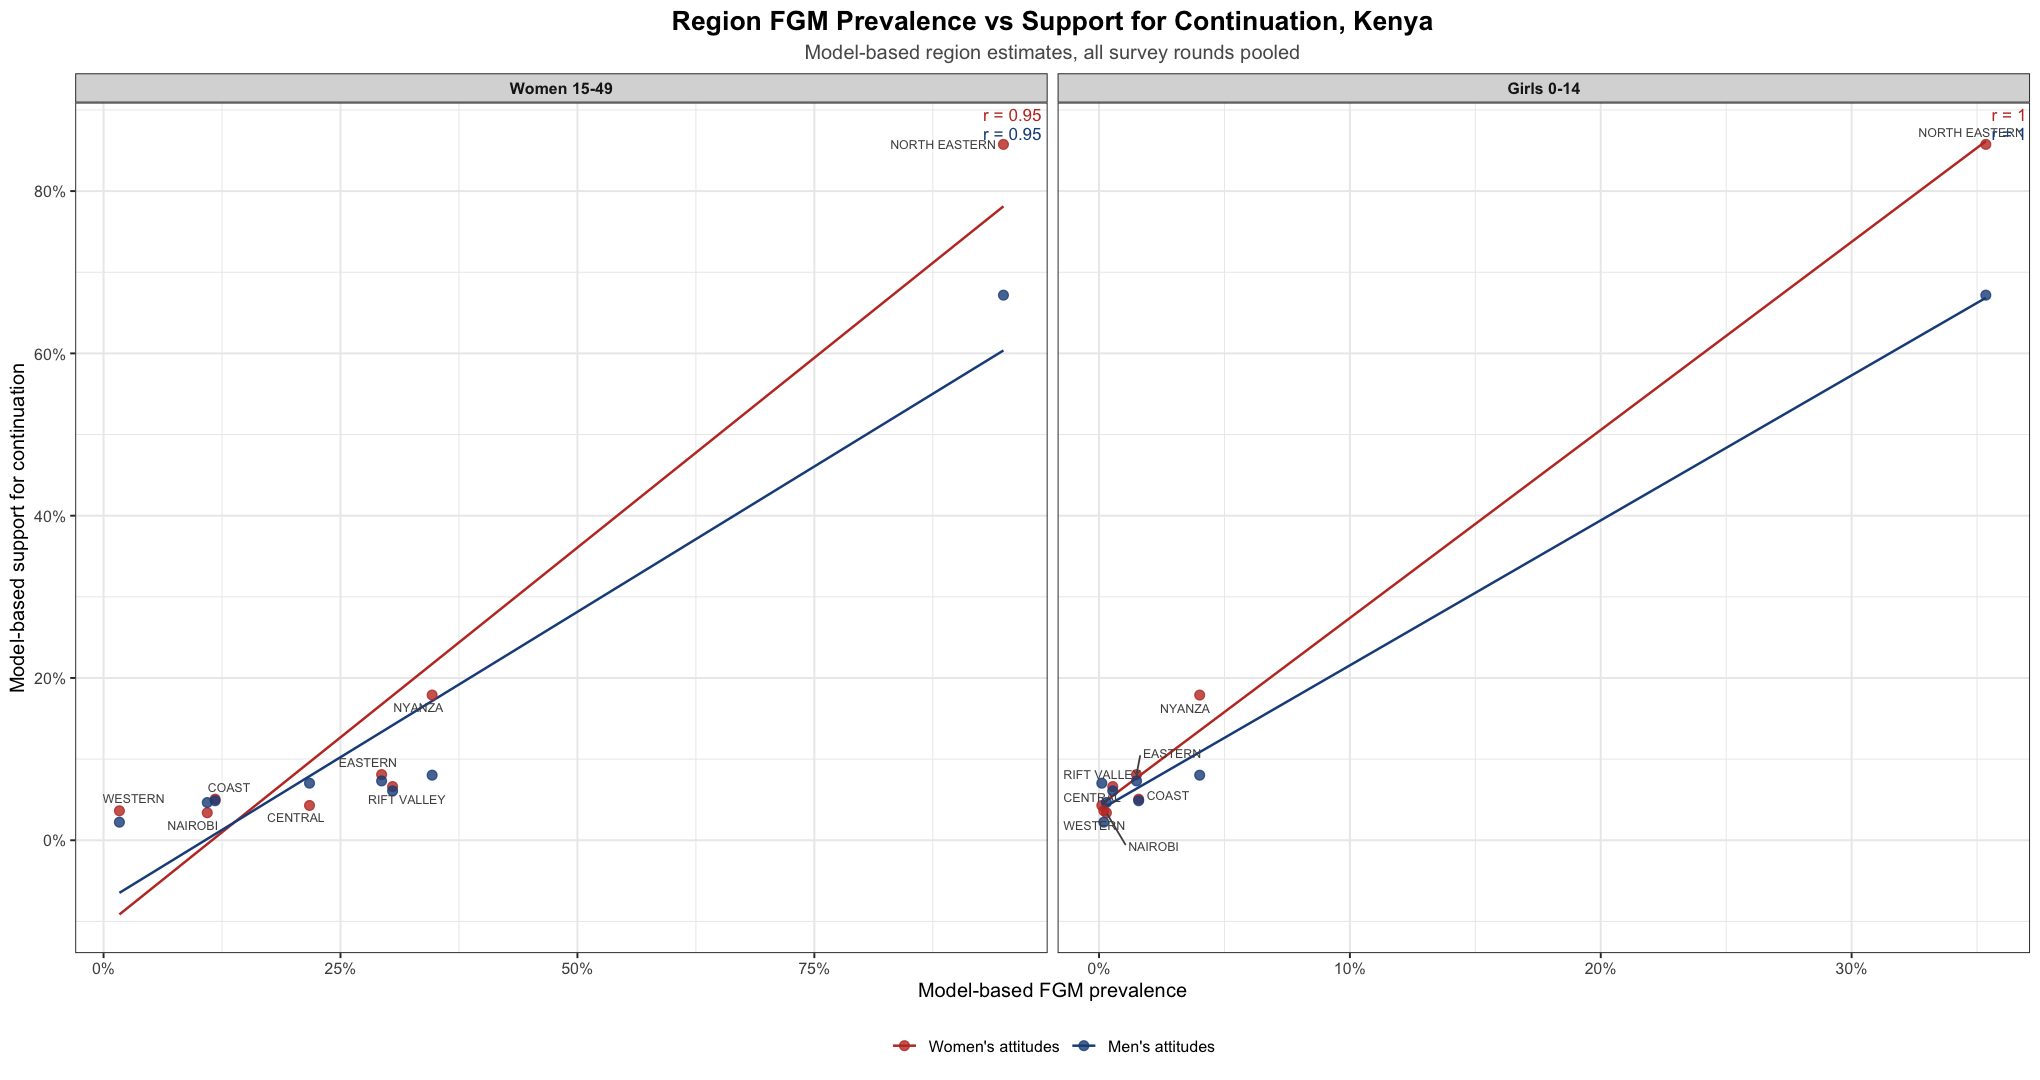

In [4]:
pair_correlations <- state_pairs |>
  dplyr::group_by(population, respondents) |>
  dplyr::summarise(regions = dplyr::n(), correlation = stats::cor(prevalence, support), .groups = "drop")
readr::write_csv(pair_correlations, file.path(dirs$region, paste0(country_iso3, "_region_correlation.csv")))
IRdisplay::display(as.data.frame(pair_correlations |> dplyr::mutate(correlation = round(correlation, 2))))

scatter <- ggplot2::ggplot(state_pairs, ggplot2::aes(prevalence, support, color = respondents)) +
  ggplot2::geom_smooth(method = "lm", se = FALSE, linewidth = 0.7, formula = y ~ x) +
  ggplot2::geom_point(alpha = 0.8, size = 2.4) +
  ggrepel::geom_text_repel(data = state_pairs |> dplyr::filter(respondents == "Women's attitudes"),
                           ggplot2::aes(label = region), size = 2.6, color = "grey30", seed = 1, max.overlaps = 12) +
  ggplot2::geom_text(data = pair_correlations, ggplot2::aes(x = Inf, y = Inf, label = paste0("r = ", round(correlation, 2)),
                     vjust = ifelse(respondents == "Women's attitudes", 1.5, 3)), hjust = 1.1, size = 3.6, show.legend = FALSE) +
  ggplot2::facet_wrap(~population, ncol = 2, scales = "free_x") +
  ggplot2::scale_color_manual(values = c("Women's attitudes" = "#C0392B", "Men's attitudes" = "#1D4E89")) +
  ggplot2::scale_x_continuous(labels = scales::percent_format(accuracy = 1)) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1)) +
  ggplot2::labs(title = paste("Region FGM Prevalence vs Support for Continuation,", country_name),
                subtitle = "Model-based region estimates, all survey rounds pooled",
                x = "Model-based FGM prevalence", y = "Model-based support for continuation", color = NULL) +
  ggplot2::theme_bw(base_size = 12) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 16, hjust = 0.5),
                 plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey35"),
                 legend.position = "bottom", strip.text = ggplot2::element_text(face = "bold"))
print(scatter)
ggplot2::ggsave(file.path(dirs$region, paste0(country_iso3, "_scatter_prevalence_vs_attitude.png")), scatter, width = 14, height = 7.5, dpi = 300, bg = "white")

## 4. Region overlay maps (pooled)

Polygon colour is pooled model-based prevalence (women 15–49 and girls 0–14); the point at
each region's centre is pooled model-based support for continuation.

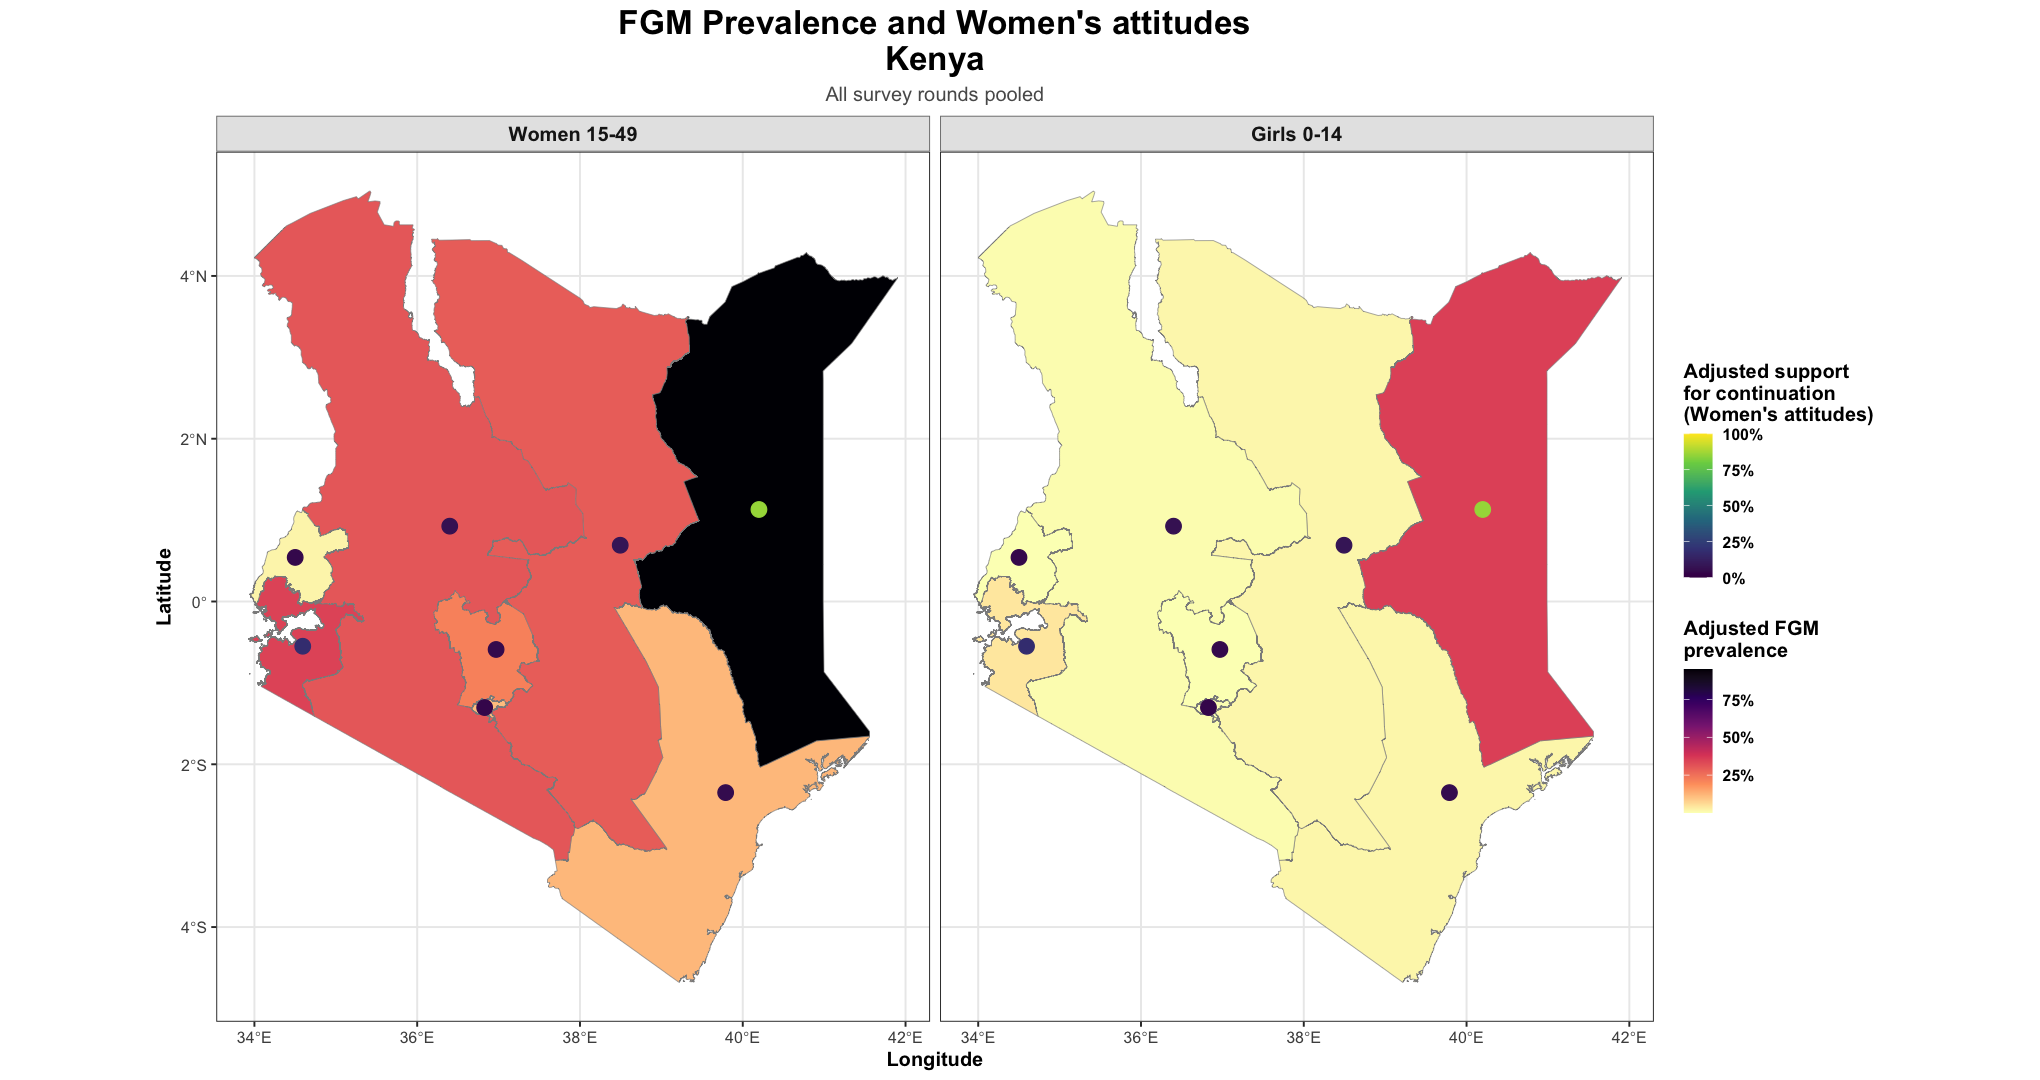

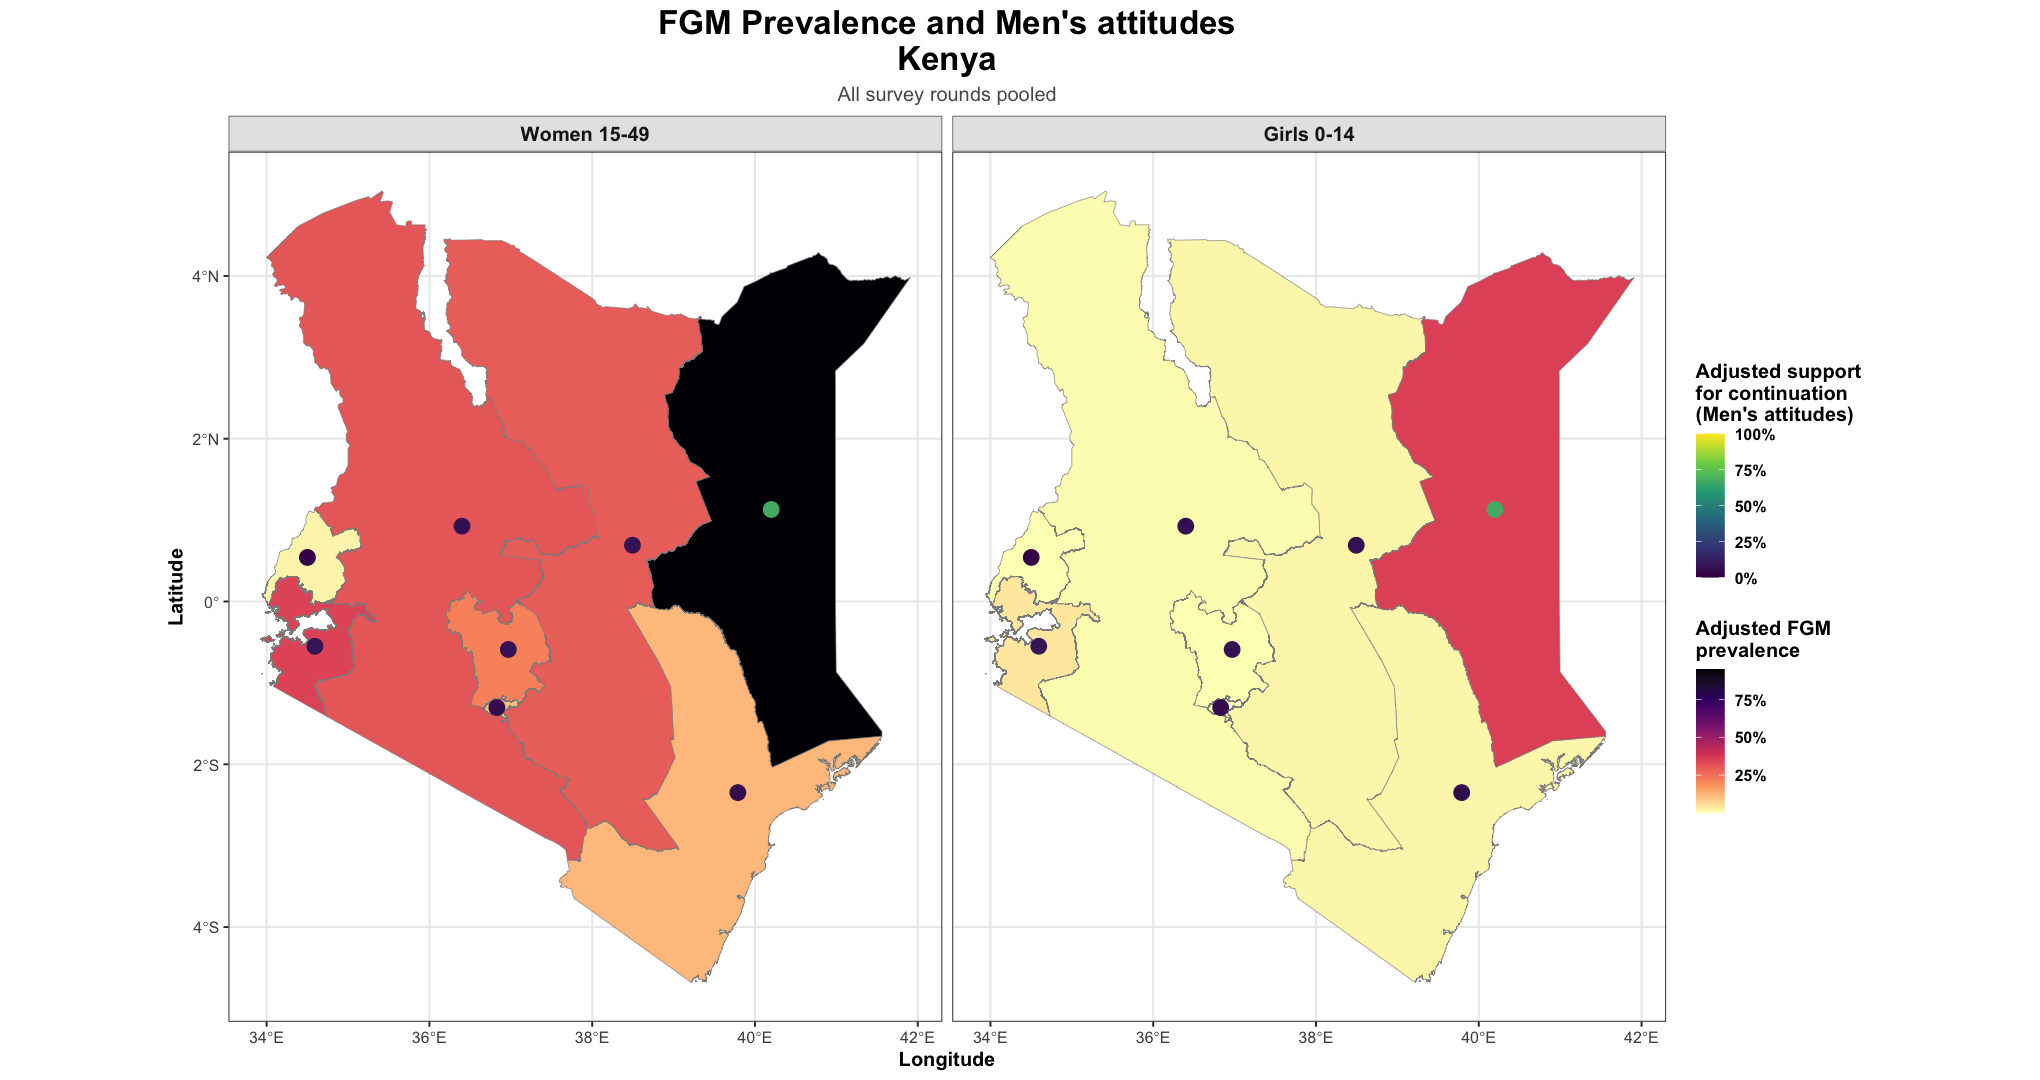

In [5]:
centroids <- suppressWarnings(sf::st_point_on_surface(boundaries)) |>
  dplyr::mutate(lon = sf::st_coordinates(geometry)[, 1], lat = sf::st_coordinates(geometry)[, 2]) |>
  sf::st_drop_geometry() |> dplyr::select(region, lon, lat)
state_overlay <- function(resp) {
  polys <- boundaries |> dplyr::left_join(prevalence_state, by = "region", relationship = "one-to-many")
  pts <- attitude_state |> dplyr::filter(respondents == resp) |> dplyr::left_join(centroids, by = "region") |>
    tidyr::crossing(population = factor(c("Women 15-49", "Girls 0-14"), levels = c("Women 15-49", "Girls 0-14")))
  ggplot2::ggplot() +
    ggplot2::geom_sf(data = polys, ggplot2::aes(fill = prevalence), color = "grey55", linewidth = 0.18) +
    ggplot2::geom_point(data = pts, ggplot2::aes(lon, lat, color = support), size = 4) +
    ggplot2::facet_wrap(~population, ncol = 2) +
    ggplot2::scale_fill_viridis_c(name = "Adjusted FGM\nprevalence", option = "magma", direction = -1,
                                  labels = scales::percent_format(accuracy = 1), oob = scales::squish) +
    ggplot2::scale_color_viridis_c(name = paste0("Adjusted support\nfor continuation\n(", resp, ")"), option = "viridis",
                                   limits = c(0, 1), labels = scales::percent_format(accuracy = 1)) +
    ggplot2::coord_sf(datum = sf::st_crs(4326)) +
    ggplot2::labs(title = paste0("FGM Prevalence and ", resp, "\n", country_name), subtitle = "All survey rounds pooled",
                  x = "Longitude", y = "Latitude") +
    ggplot2::theme_bw(base_size = 12) +
    ggplot2::theme(text = ggplot2::element_text(face = "bold"), plot.title = ggplot2::element_text(size = 20, hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey35", face = "plain"),
                   strip.text = ggplot2::element_text(size = 12), strip.background = ggplot2::element_rect(fill = "grey90", color = "grey50"))
}
for (resp in c("Women's attitudes", "Men's attitudes")) {
  p <- state_overlay(resp); print(p)
  ggplot2::ggsave(file.path(dirs$region, paste0(country_iso3, "_region_overlay_prevalence_",
                                               ifelse(resp == "Women's attitudes", "women", "men"), "_attitudes.png")),
                  p, width = 17, height = 9, dpi = 300, bg = "white")
}

## 5. Cluster-level attitudes, all DHS rounds

V1 cluster model with V2 data, fitted to each DHS round with GPS: covariate-adjusted
cluster-level BYM2 on a k-nearest-neighbour graph (k = 6) of that round's cluster
locations, RW2 age and normalized weights, separately for women (with own FGM status) and
men. All three rounds collect the covariates used. Clusters with withheld coordinates (0, 0) are excluded. Fitted probabilities are
averaged with the survey weights within each cluster.

In [6]:
gps <- purrr::imap_dfr(gps_paths, function(path, round_id) {
  sf::st_read(path, quiet = TRUE) |> sf::st_drop_geometry() |>
    dplyr::transmute(cluster = paste(round_id, DHSCLUST, sep = "-"), lon = LONGNUM, lat = LATNUM)
}) |> dplyr::filter(!(lon == 0 & lat == 0))

fit_cluster_attitude <- function(data, round_id, fixed_candidates, seed) {
  d <- data |> dplyr::filter(survey_id == round_id) |> dplyr::inner_join(gps, by = "cluster")
  fixed_terms <- fixed_candidates[vapply(fixed_candidates, function(v)
    mean(!is.na(d[[v]])) >= 0.95 && dplyr::n_distinct(stats::na.omit(d[[v]])) > 1, logical(1))]
  d <- d |> tidyr::drop_na(dplyr::all_of(fixed_terms), age) |>
    dplyr::mutate(dplyr::across(dplyr::all_of(fixed_terms), factor))
  lookup <- d |> dplyr::group_by(cluster, region) |>
    dplyr::summarise(lon = mean(lon), lat = mean(lat), n_unweighted = dplyr::n(), .groups = "drop") |>
    dplyr::arrange(cluster) |> dplyr::mutate(cluster_id = dplyr::row_number())
  d <- d |> dplyr::left_join(lookup |> dplyr::select(cluster, cluster_id), by = "cluster") |>
    dplyr::mutate(age_id = as.integer(age - min(age) + 1L), pseudo_weight = weight / mean(weight))
  coords <- sf::st_as_sf(lookup, coords = c("lon", "lat"), crs = 4326) |> sf::st_transform(32630) |> sf::st_coordinates()
  graph <- spdep::nb2mat(spdep::knn2nb(spdep::knearneigh(coords, k = k_neighbours), sym = TRUE), style = "B", zero.policy = TRUE)
  form <- stats::as.formula(paste0("supports_continuation ~ ", paste(fixed_terms, collapse = " + "),
    " + f(age_id, model = 'rw2', constr = TRUE, scale.model = TRUE) + f(cluster_id, model = 'bym2', graph = graph, scale.model = TRUE)"))
  fit <- INLA::inla(form, family = "binomial", data = d, weights = d$pseudo_weight,
                    control.predictor = list(compute = TRUE, link = 1), control.compute = list(config = TRUE),
                    control.inla = list(control.vb = list(enable = FALSE)))
  set.seed(seed)
  samples <- INLA::inla.posterior.sample(posterior_draws, fit, use.improved.mean = FALSE, skew.corr = FALSE)
  rows <- grep("^Predictor:", rownames(samples[[1]]$latent))
  rows <- rows[order(as.integer(sub("^Predictor:", "", rownames(samples[[1]]$latent)[rows])))]
  idx <- factor(d$cluster_id, levels = lookup$cluster_id)
  draws <- vapply(samples, function(s) tapply(stats::plogis(as.numeric(s$latent[rows, 1])) * d$weight, idx, sum) / tapply(d$weight, idx, sum),
                  numeric(nrow(lookup)))
  message(sprintf("%s: %d clusters, %d respondents; covariates: %s", round_id, nrow(lookup), nrow(d), paste(fixed_terms, collapse = ", ")))
  lookup |> dplyr::mutate(survey_id = round_id, adjusted_support = rowMeans(draws),
                          lower_ci = apply(draws, 1, stats::quantile, 0.025, names = FALSE),
                          upper_ci = apply(draws, 1, stats::quantile, 0.975, names = FALSE))
}

attitude_women <- readRDS(file.path(analysis_dir, paste0(country_iso3, "_attitude_women.rds"))) |>
  dplyr::mutate(own_status = factor(own_status, levels = c(0, 1), labels = c("Not cut", "Cut")))
attitude_men <- readRDS(file.path(analysis_dir, paste0(country_iso3, "_attitude_men.rds")))
fixed_women <- c("own_status", "education", "wealth", "religion", "ethnicity", "urban_rural")
women_rounds <- intersect(names(gps_paths), unique(attitude_women$survey_id))
men_rounds <- intersect(names(gps_paths), unique(attitude_men$survey_id))
clusters_women <- purrr::map_dfr(seq_along(women_rounds), function(i)
  fit_cluster_attitude(attitude_women, women_rounds[i], fixed_women, 20260922L + i))
clusters_men <- purrr::map_dfr(seq_along(men_rounds), function(i)
  fit_cluster_attitude(attitude_men, men_rounds[i], setdiff(fixed_women, "own_status"), 20261022L + i))
readr::write_csv(clusters_women, file.path(dirs$cluster, paste0(country_iso3, "_adjusted_attitude_clusters_women.csv")))
readr::write_csv(clusters_men, file.path(dirs$cluster, paste0(country_iso3, "_adjusted_attitude_clusters_men.csv")))
IRdisplay::display(as.data.frame(dplyr::bind_rows(clusters_women |> dplyr::mutate(respondents = "Women"),
                                                  clusters_men |> dplyr::mutate(respondents = "Men")) |>
  dplyr::count(respondents, survey_id, name = "clusters")))

DHS 2008: 397 clusters, 7586 respondents; covariates: own_status, education, wealth, religion, ethnicity, urban_rural

Warning message in spdep::knn2nb(spdep::knearneigh(coords, k = k_neighbours), sym = TRUE):
“neighbour object has 2 sub-graphs”
DHS 2014: 1584 clusters, 13990 respondents; covariates: own_status, education, wealth, religion, ethnicity, urban_rural

Warning message in spdep::knn2nb(spdep::knearneigh(coords, k = k_neighbours), sym = TRUE):
“neighbour object has 2 sub-graphs”
DHS 2022: 1689 clusters, 15890 respondents; covariates: own_status, education, wealth, religion, ethnicity, urban_rural

Warning message in spdep::knn2nb(spdep::knearneigh(coords, k = k_neighbours), sym = TRUE):
“neighbour object has 2 sub-graphs”
DHS 2014: 1574 clusters, 11420 respondents; covariates: education, wealth, religion, ethnicity, urban_rural

Warning message in spdep::knn2nb(spdep::knearneigh(coords, k = k_neighbours), sym = TRUE):
“neighbour object has 2 sub-graphs”
DHS 2022: 1684 cluster

respondents,survey_id,clusters
<chr>,<chr>,<int>
Men,DHS 2014,1574
Men,DHS 2022,1684
Women,DHS 2008,397
Women,DHS 2014,1584
Women,DHS 2022,1689


## 6. Cluster overlays (pooled)

Two-panel overlays as in V1: pooled model-based prevalence among women and girls, with
the cluster-level attitude points from every DHS round together, one figure for women's
attitudes and one for men's. Point size uses one fixed scale in both figures.

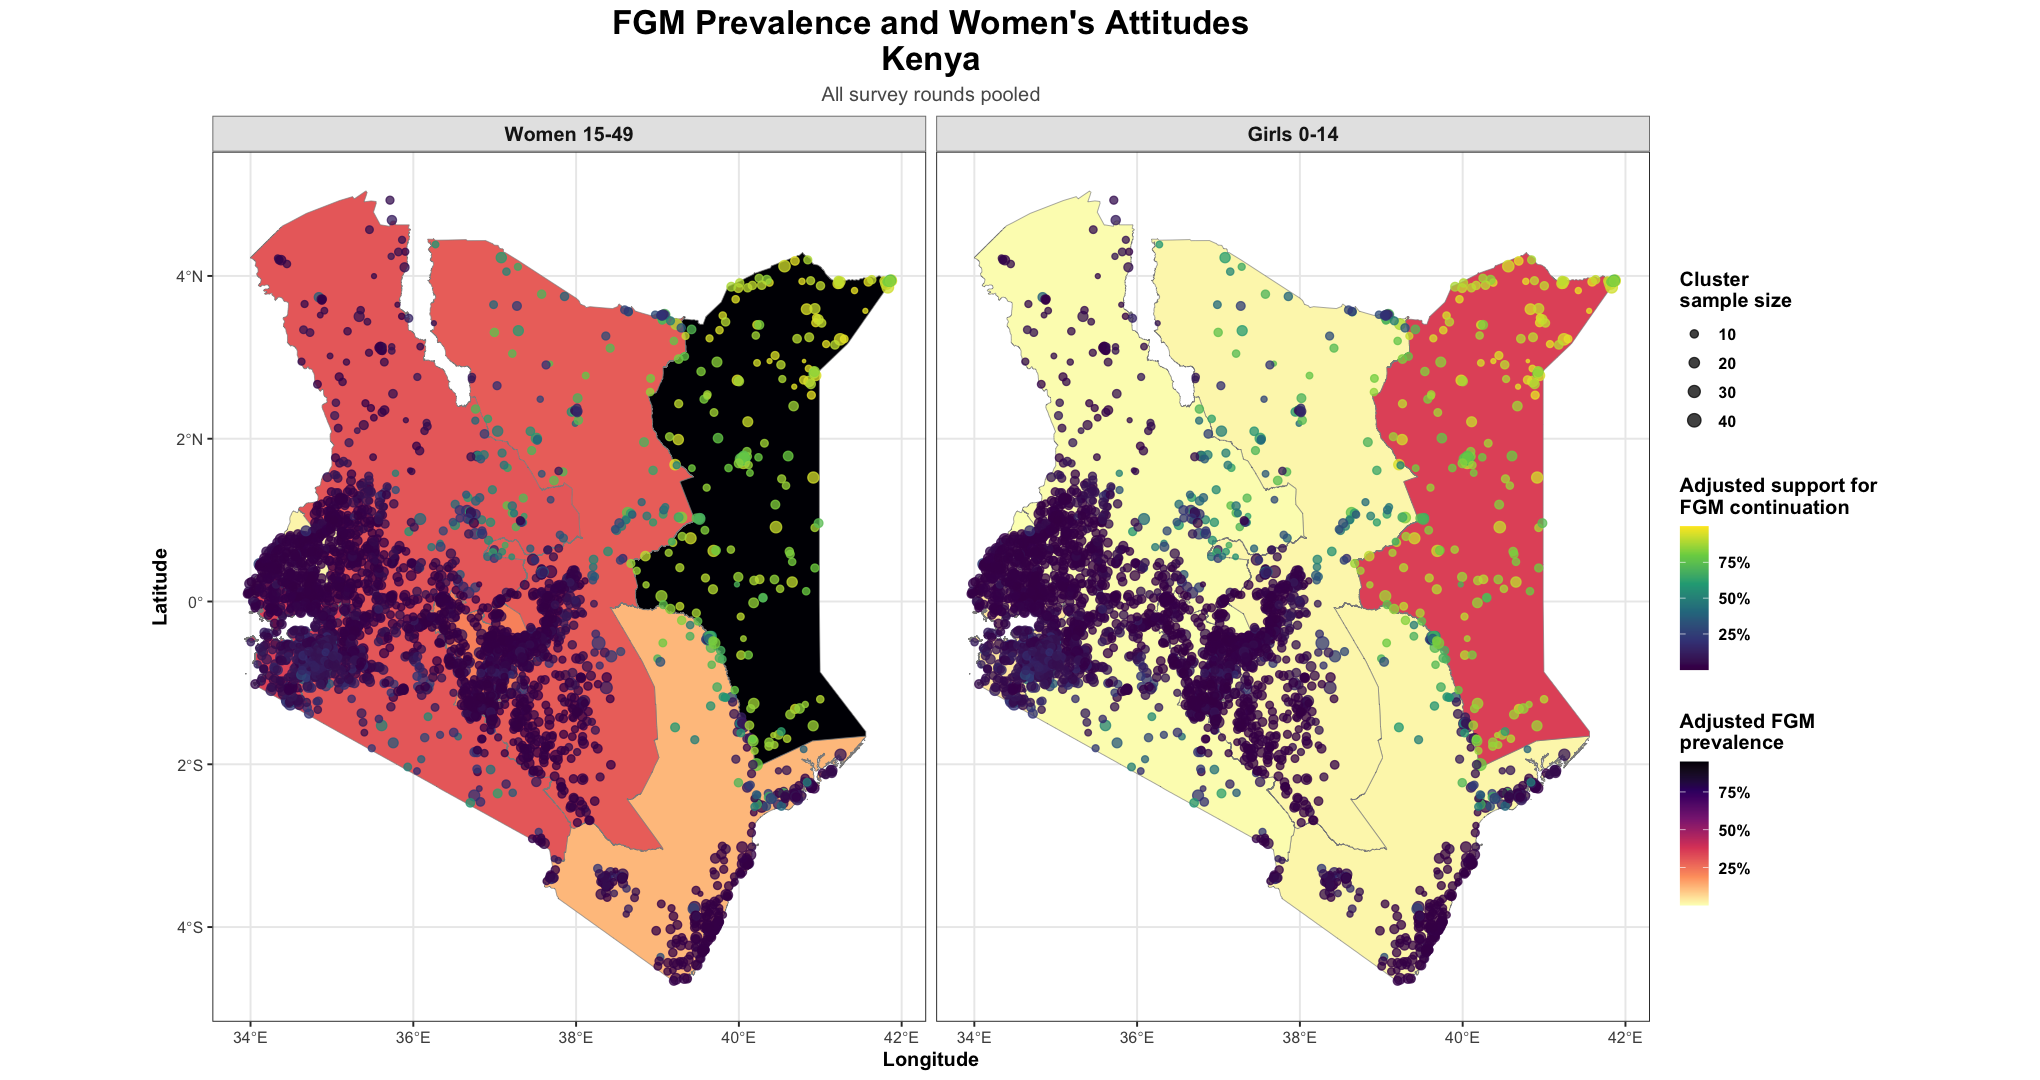

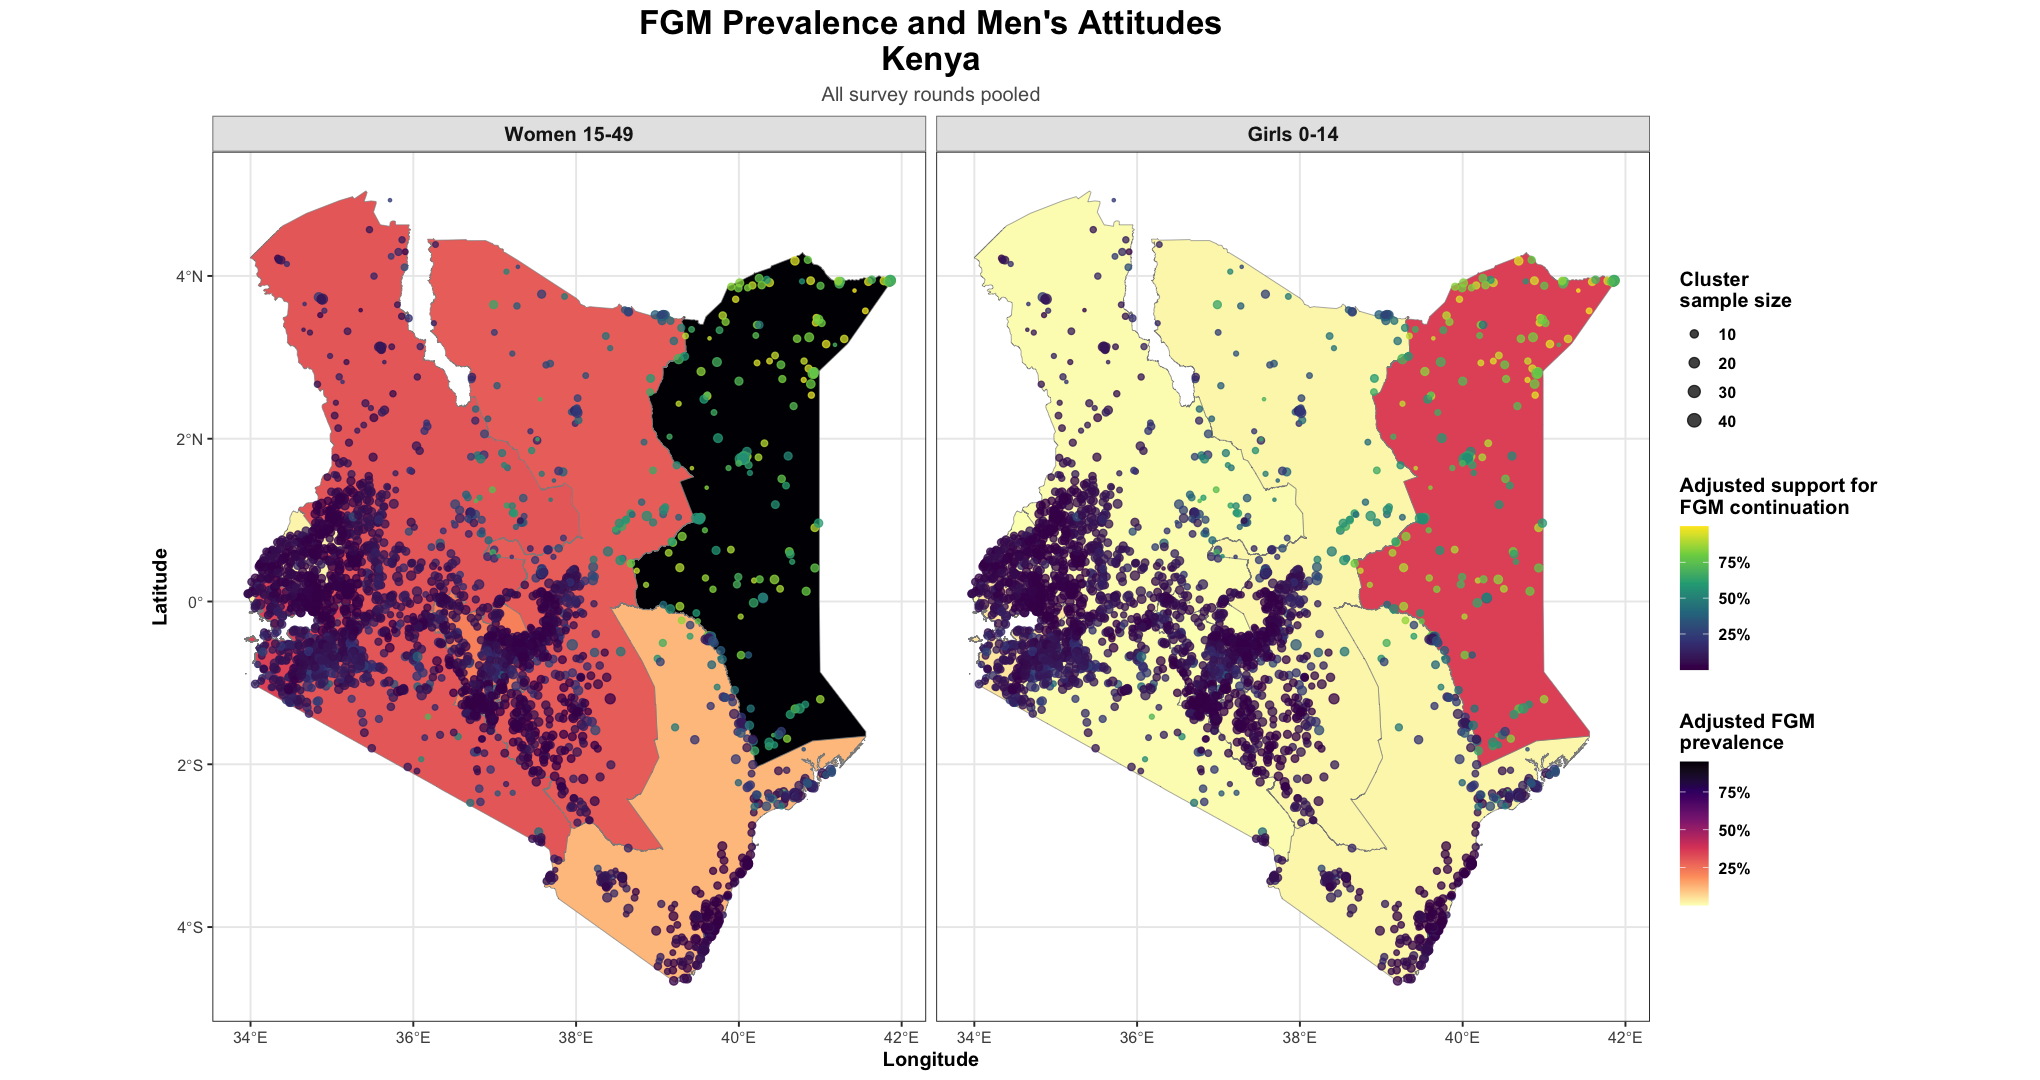

In [7]:
size_limits <- c(1, max(clusters_women$n_unweighted, clusters_men$n_unweighted))
pooled_overlay <- function(clusters, resp_label) {
  panels <- c("Women 15-49", "Girls 0-14")
  polys <- boundaries |> dplyr::left_join(prevalence_state, by = "region", relationship = "one-to-many")
  pts <- tidyr::crossing(clusters, population = factor(panels, levels = panels))
  ggplot2::ggplot() +
    ggplot2::geom_sf(data = polys, ggplot2::aes(fill = prevalence), color = "grey55", linewidth = 0.18) +
    ggplot2::geom_point(data = pts, ggplot2::aes(lon, lat, color = adjusted_support, size = n_unweighted), alpha = 0.75) +
    ggplot2::facet_wrap(~population, ncol = 2) +
    ggplot2::scale_fill_viridis_c(name = "Adjusted FGM\nprevalence", option = "magma", direction = -1,
                                  labels = scales::percent_format(accuracy = 1), oob = scales::squish) +
    ggplot2::scale_color_viridis_c(name = "Adjusted support for\nFGM continuation", option = "viridis", limits = c(0, 1),
                                   breaks = c(0.25, 0.5, 0.75), labels = scales::percent_format(accuracy = 1)) +
    ggplot2::scale_size_continuous(name = "Cluster\nsample size", range = c(0.6, 3.5), limits = size_limits,
                                   breaks = scales::breaks_pretty(4)(size_limits)) +
    ggplot2::coord_sf(datum = sf::st_crs(4326)) +
    ggplot2::labs(title = paste0("FGM Prevalence and ", resp_label, "\n", country_name),
                  subtitle = "All survey rounds pooled", x = "Longitude", y = "Latitude") +
    ggplot2::theme_bw(base_size = 12) +
    ggplot2::theme(text = ggplot2::element_text(face = "bold"), plot.title = ggplot2::element_text(size = 20, hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey35", face = "plain"),
                   strip.text = ggplot2::element_text(size = 12), strip.background = ggplot2::element_rect(fill = "grey90", color = "grey50"))
}
women_overlay <- pooled_overlay(clusters_women, "Women's Attitudes")
men_overlay <- pooled_overlay(clusters_men, "Men's Attitudes")
print(women_overlay); print(men_overlay)
ggplot2::ggsave(file.path(dirs$cluster, paste0(country_iso3, "_combined_prevalence_attitude_overlay_women.png")), women_overlay,
                width = 17, height = 9, dpi = 300, bg = "white")
ggplot2::ggsave(file.path(dirs$cluster, paste0(country_iso3, "_combined_prevalence_attitude_overlay_men.png")), men_overlay,
                width = 17, height = 9, dpi = 300, bg = "white")

## Results

**1. Province level.** Prevalence and support for continuation are strongly correlated across the
8 provinces (0.95–1.00), entirely because North Eastern combines very high prevalence and support.

**2. County level (DHS 2014 and 2022).** Across 47 counties, women's support correlates 0.93 with
girls' prevalence and 0.79 with women's prevalence; men's support 0.91 and 0.79. Women's and men's
support are themselves almost identical across counties (0.98), so their links with prevalence can
only be separated weakly: for girls' prevalence, women's support remains associated (+7.3 points
per standard deviation, p = 0.003) and men's adds nothing (p = 0.57).

**3. Cluster maps.** Clusters where most women support continuation are almost all in North
Eastern (97% of its clusters, against 0–10% elsewhere); for men, 84% of North Eastern clusters.

## Interpretation

Polygon colour is model-based FGM prevalence; points are model-based support for
continuation among women or men, pooling all survey rounds; cluster points come from every
DHS round with GPS (MICS has none). Spatial coincidence is descriptive, not causal.

In [8]:
cat("Comparison outputs saved to:", normalizePath(output_dir), "\n")
tibble::tibble(file = list.files(output_dir, recursive = TRUE))

Comparison outputs saved to: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/Final FGM Results/Kenya/V2/03_Outputs/KEN/Prevalence_Attitude_Comparison 


file
<chr>
01_Region_Level/KEN_region_correlation.csv
01_Region_Level/KEN_region_overlay_prevalence_men_attitudes.png
01_Region_Level/KEN_region_overlay_prevalence_women_attitudes.png
01_Region_Level/KEN_region_prevalence_vs_attitude.csv
01_Region_Level/KEN_scatter_prevalence_vs_attitude.png
02_Cluster_Level/KEN_adjusted_attitude_clusters_men.csv
02_Cluster_Level/KEN_adjusted_attitude_clusters_women.csv
02_Cluster_Level/KEN_combined_prevalence_attitude_overlay_men.png
02_Cluster_Level/KEN_combined_prevalence_attitude_overlay_women.png
